In [1]:
import csv

In [2]:
with open('mix/TV.csv') as f:
    data = csv.DictReader(f)
    stations = list(data)

In [5]:
stations[:3]

[{'Callsign': 'KCRA-TV', 'Frequency': '599', 'Signal Margin (dB)': '63.32'},
 {'Callsign': 'KTXL', 'Frequency': '521', 'Signal Margin (dB)': '64.36'},
 {'Callsign': 'KOVR', 'Frequency': '539', 'Signal Margin (dB)': '63.51'}]

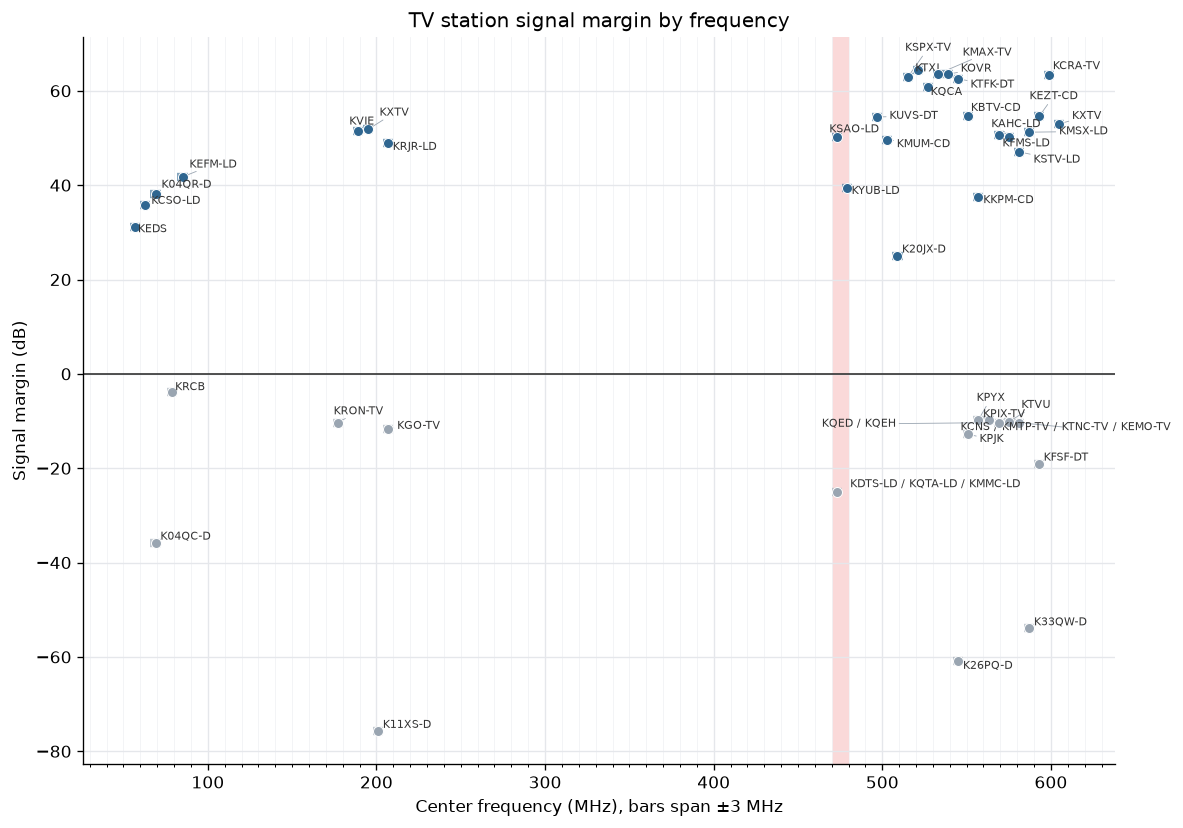

In [6]:
import matplotlib.pyplot as plt
from adjustText import adjust_text
from matplotlib.ticker import MultipleLocator

points = []
for s in stations:
    callsign = " / ".join(s["Callsign"].split())  # multi-station cells contain newlines
    points.append((float(s["Frequency"]), float(s["Signal Margin (dB)"]), callsign))

HUE = "#2F6690"    # positive margin
MUTED = "#9AA5B1"  # below-zero margin

fig, ax = plt.subplots(figsize=(10, 7), dpi=120)
texts = []
for freq, margin, name in points:
    color = HUE if margin >= 0 else MUTED
    ax.hlines(margin, freq - 3, freq + 3, color=color, linewidth=5, alpha=0.6, zorder=2)
    ax.scatter(freq, margin, s=36, color=color, edgecolors="white", linewidths=0.6, zorder=3)
    texts.append(ax.text(freq, margin, name, fontsize=6.5, color="#333333"))
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="#9AA5B1", lw=0.5))
ax.axvspan(470, 480, color="#F8C9C9", alpha=0.7, linewidth=0, zorder=0)  # highlight 470-480 MHz

ax.axhline(0, color="#333333", linewidth=1, zorder=1)
ax.set_xlabel("Center frequency (MHz), bars span ±3 MHz")
ax.set_ylabel("Signal margin (dB)")
ax.set_title("TV station signal margin by frequency")
ax.xaxis.set_minor_locator(MultipleLocator(10))  # subdivisions every 10 MHz
ax.grid(which="major", color="#E5E7EB", linewidth=0.8)
ax.grid(which="minor", axis="x", color="#F1F3F5", linewidth=0.5)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()
